# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

## Ranking results
Measured cpu runtime on the ranking process.

In [44]:
import pandas as pd
import os

rankdata = pd.DataFrame()
for dataset in pd.read_csv('../data/rebate.csv').itertuples():
    ranking_path = os.path.join('../results/ranking', dataset.path + '.csv')
    if os.path.exists(ranking_path):
        data = pd.read_csv(ranking_path)
        dataset_id = '{} [p={},n={},h={},edm={}]'.format(dataset.theme, dataset.p, dataset.n, dataset.heritability, dataset.edm)
        data['dataset'] = dataset_id
        rankdata = rankdata.append(data)

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

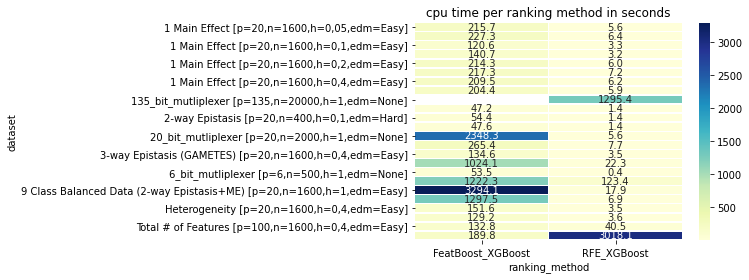

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(rankdata, values='cpu_time', index=['dataset'], columns=['ranking_method'])
sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

In [4]:
# sns.catplot(x="dataset_no", y="cpu_time", hue="ranking_method", 
#             data=all_results, col="dataset", col_wrap=4, kind="bar", 
#             facet_kws={'sharey': False})

## Validation results
Validation using KNN.

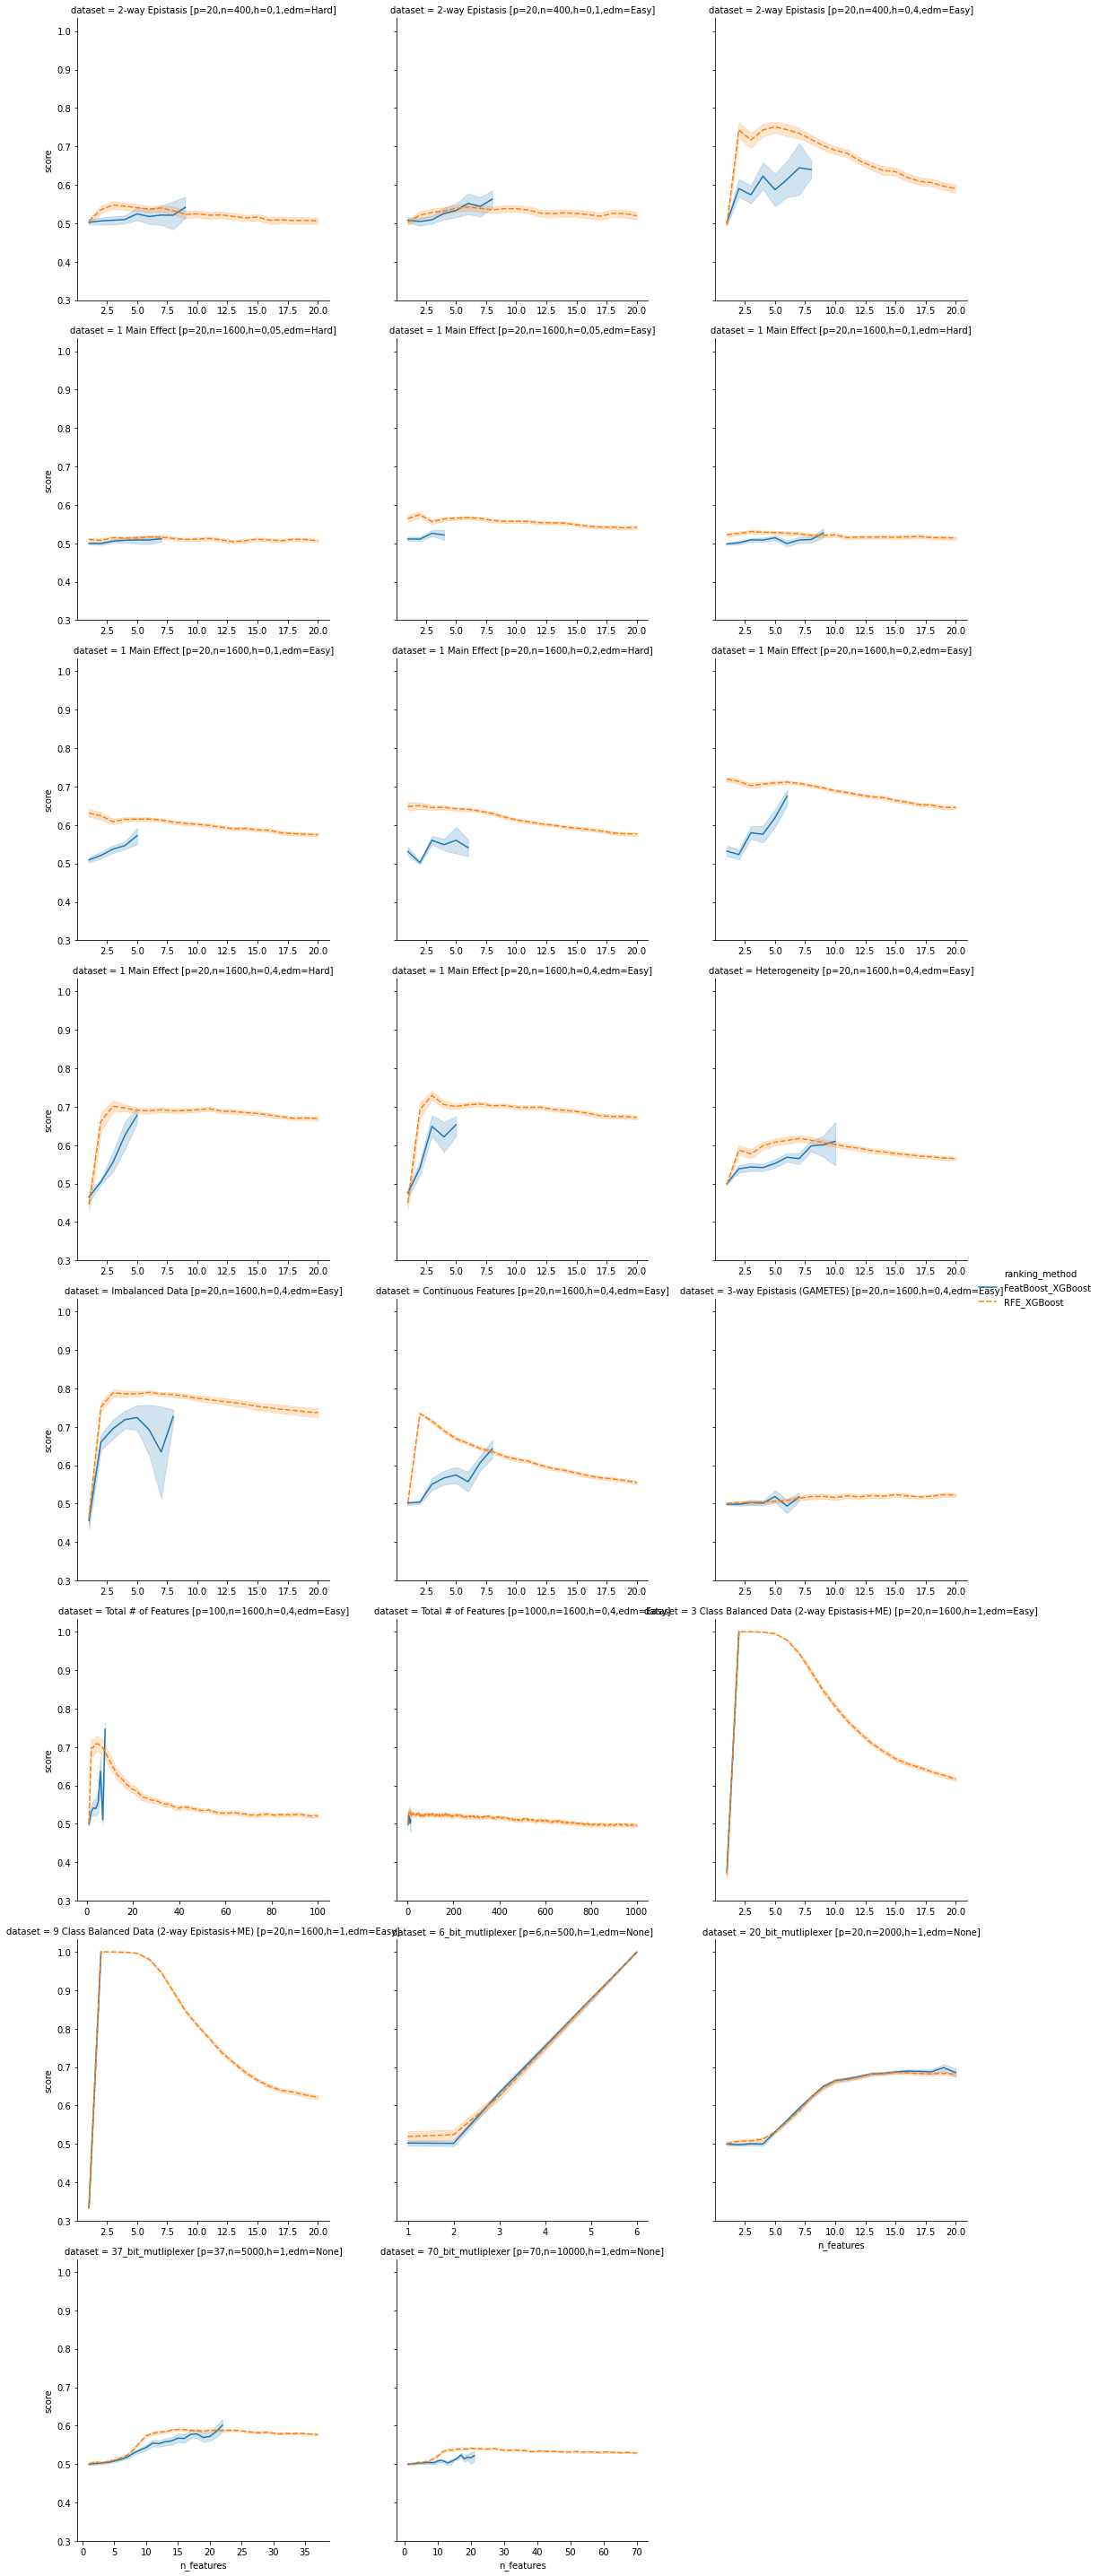

In [46]:
valdata = pd.DataFrame()
for dataset in pd.read_csv('../data/rebate.csv').itertuples():
    val_path = os.path.join('../results/validation', dataset.path + '.csv')
    if os.path.exists(val_path):
        data = pd.read_csv(val_path)
        dataset_id = '{} [p={},n={},h={},edm={}]'.format(dataset.theme, dataset.p, dataset.n, dataset.heritability, dataset.edm)
        data['dataset'] = dataset_id
        valdata = valdata.append(data)

g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method", kind="line",
            col_wrap=3,
            facet_kws={'sharex': False},
            data=valdata)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: int(x)))